# 03 · DRAG orders 1 and 2 on the BARQ X gate

Notebook 02 showed two errors of the bare X gate on a three-level system:
leakage to $|2\rangle$, and a coherent Stark shift inside the qubit that also
re-opens a first-order dephasing error. This notebook applies DRAG to the
finished pulse and repeats the two-level and three-level checks.

DRAG is a post-processing step. It does not change the curve or the
optimizer. With $\nu=T_g\alpha$ and $\varepsilon=\Omega e^{i\Phi}$:

- order 1 adds the derivative quadrature $-i\beta\,\dot\varepsilon/\nu$ and
  the AC Stark detuning,
- order 2 adds the next terms in Motzoi's expansion.

`beta` scales only the derivative quadrature. The formulas assume a resonant
pulse. This TTC pulse has a constant detuning $T_g\Delta\approx 0.85$, while
$|T_g\alpha|\approx 63$ at 50 ns, so that detuning is a correction of about
one percent. `simulate_qutrit` and `first_order_leakage` keep the detuning
exactly; the DRAG formula does not.

Run notebooks 01 and 02 first.

In [1]:
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from qurveros import drag, plottools
from qurveros.qubit_bench import noise_experiments, simulator
import qurveros.plot_configs

import xgate_setup as xs

matplotlib.rcParams['figure.dpi'] = 150

u_target = xs.U_TARGET
bare = xs.xgate_control()
tg_alpha = xs.tg_alpha()
orders = (0, 1, 2)
colors = {0: 'k', 1: 'tab:blue', 2: 'tab:orange'}

pulses = {order: drag.apply_drag(bare, tg_alpha, order=order, beta=1.0, lam=xs.LAM)
          for order in orders}
print(f'T_g alpha = {tg_alpha:.2f} at {xs.GATE_TIME_NS:.0f} ns, lambda = {xs.LAM:.3f}')

T_g alpha = -62.83 at 50 ns, lambda = 1.414


## The corrected pulses

Order 0 is the BARQ pulse. Orders 1 and 2 add a quadrature component, so
the envelope $\Omega$ and the phase $\Phi$ both change, and a time-dependent
detuning appears on top of the constant TTC value.

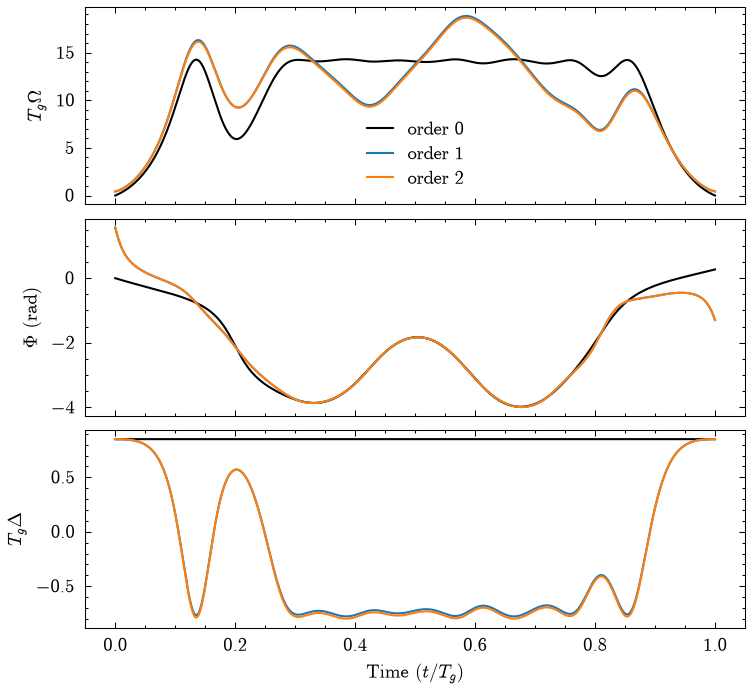

In [2]:
times = bare['times']
fig, axs = plt.subplots(3, 1, sharex=True, figsize=(5, 4.6), layout='constrained')
for order, pulse in pulses.items():
    axs[0].plot(times, pulse['omega'], color=colors[order], label=f'order {order}')
    axs[1].plot(times, np.unwrap(pulse['phi']), color=colors[order])
    axs[2].plot(times, pulse['delta'], color=colors[order])
axs[0].set_ylabel(r'$T_g\Omega$')
axs[1].set_ylabel(r'$\Phi$ (rad)')
axs[2].set_ylabel(r'$T_g\Delta$')
axs[2].set_xlabel(r'Time $(t/T_g)$')
axs[0].legend()
plt.show()

## Scan of the DRAG scale $\beta$

`drag_order_experiment` corrects the pulse at each order and each $\beta$
and simulates the qutrit. $\beta=0$ returns the original pulse for every
order. $\beta=1$ is the analytic coefficient of the derivative quadrature.

DRAG order comparison



DRAG order 0:	22.22 %

DRAG order 0:	55.56 %

DRAG order 0:	88.89 %

DRAG order 0:	100.00%

DRAG order 1:	22.22 %

...

DRAG order 1:	88.89 %

DRAG order 1:	100.00%

DRAG order 2:	11.11 %

DRAG order 2:	44.44 %

DRAG order 2:	77.78 %

DRAG order 2:	100.00%


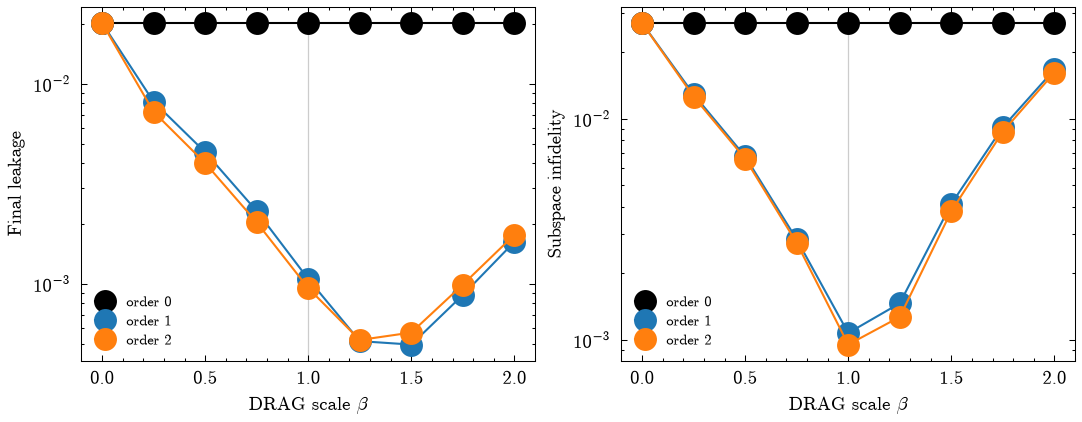

,order 0,order 1,order 2
leakage,0.020133,1.057020e-03,0.000951
peak leakage,0.051293,1.543495e-02,0.014812
subspace infidelity,0.027106,1.074791e-03,0.000953
subspace phase (rad),0.947618,1.024755e+00,1.037768
Fourier proxy,0.008414,1.506120e-13,0.000009


In [3]:
betas = np.linspace(0.0, 2.0, 9)
scan = noise_experiments.drag_order_experiment(
    bare, u_target, tg_alpha, orders=orders, betas=betas, lam=xs.LAM)

fig, axs = plt.subplots(1, 2, figsize=(7.2, 2.8), layout='constrained', sharex=True)
for index, order in enumerate(scan['orders']):
    axs[0].semilogy(scan['betas'], scan['leakage'][index], 'o-',
                    color=colors[int(order)], label=f'order {int(order)}')
    axs[1].semilogy(scan['betas'], scan['subspace_infidelity'][index], 'o-',
                    color=colors[int(order)], label=f'order {int(order)}')
axs[0].set_ylabel('Final leakage')
axs[1].set_ylabel('Subspace infidelity')
for ax in axs:
    ax.set_xlabel(r'DRAG scale $\beta$')
    ax.axvline(1.0, color='0.8', lw=0.6, zorder=0)
    ax.legend(fontsize=7)
plt.show()

at_one = int(np.argmin(np.abs(scan['betas'] - 1.0)))
pd.DataFrame({
    f'order {int(order)}': {
        'leakage': scan['leakage'][index, at_one],
        'peak leakage': scan['peak_leakage'][index, at_one],
        'subspace infidelity': scan['subspace_infidelity'][index, at_one],
        'subspace phase (rad)': scan['subspace_phase'][index, at_one],
        'Fourier proxy': scan['leakage_estimate'][index, at_one],
    }
    for index, order in enumerate(scan['orders'])
})

**Reading the scan.** Leakage keeps falling past $\beta=1$ and is lowest
near $\beta=1.5$. The subspace infidelity, which also counts the rotation
error inside the qubit, is lowest at $\beta=1$. Past that point the extra
quadrature costs more fidelity than it saves in leakage. The rest of this
notebook uses $\beta=1$.

The constant TTC detuning is why the leakage minimum is not exactly at the
analytic value: the DRAG formula assumes resonance.

## Two-level checks

DRAG changes the qubit pulse, so the gate is no longer a perfect X, and the
curve is no longer exactly closed. The error vectors
$\vec r_z$ and $\vec r_\varepsilon$ measure that directly. They are
calculated from the propagator; the dashed lines below are the infidelities
they predict, $(T_g\delta_z)^2|\vec r_z|^2/6$ and
$\varepsilon^2|\vec r_\varepsilon|^2/6$.

In [4]:
tg_delta_z = np.logspace(-3, 0, 13)
epsilons = np.logspace(-4, -1, 13)

qubit_rows = {}
qubit_sweeps = {}
for order, pulse in pulses.items():
    simulated = simulator.simulate_control_dict(pulse, u_target)
    vectors = simulator.first_order_error_vectors(pulse)
    qubit_sweeps[order] = {
        'dephasing': xs.sensitivity_sweep(pulse, 'dephasing', tg_delta_z, u_target=u_target),
        'amplitude': xs.sensitivity_sweep(pulse, 'amplitude', epsilons, u_target=u_target),
        'vectors': vectors,
    }
    qubit_rows[f'order {order}'] = {
        'fidelity to X': simulated['avg_gate_fidelity'],
        '|r_z|': vectors['r_z_norm'],
        '|r_eps|': vectors['r_epsilon_norm'],
    }
pd.DataFrame(qubit_rows)

,order 0,order 1,order 2
fidelity to X,1.000000e+00,0.997551,0.997493
|r_z|,6.709620e-12,0.105375,0.104686
|r_eps|,1.089444e-02,0.262600,0.370036


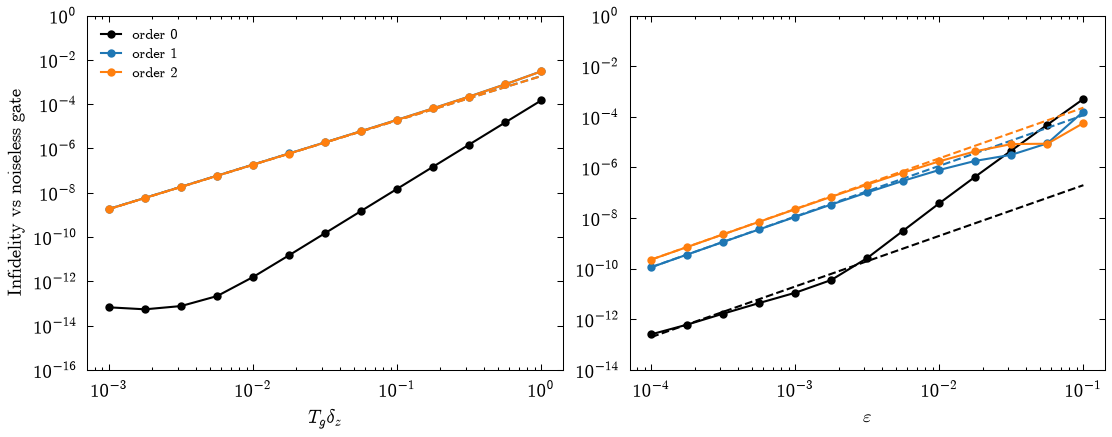

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(7.4, 2.9), layout='constrained')
for order, sweep in qubit_sweeps.items():
    vectors = sweep['vectors']
    axs[0].loglog(tg_delta_z, sweep['dephasing']['sensitivity'], 'o-', ms=3,
                  color=colors[order], label=f'order {order}')
    axs[0].loglog(tg_delta_z, (tg_delta_z * vectors['r_z_norm'])**2 / 6, '--',
                  color=colors[order])
    axs[1].loglog(epsilons, sweep['amplitude']['sensitivity'], 'o-', ms=3,
                  color=colors[order], label=f'order {order}')
    axs[1].loglog(epsilons, (epsilons * vectors['r_epsilon_norm'])**2 / 6, '--',
                  color=colors[order])
axs[0].set_xlabel(r'$T_g\delta_z$')
axs[1].set_xlabel(r'$\varepsilon$')
axs[0].set_ylabel('Infidelity vs noiseless gate')
axs[0].set_ylim(1e-16, 1)
axs[1].set_ylim(1e-14, 1)
axs[0].legend(fontsize=7)
plt.show()

**Reading the two-level sweeps.**

- **Order 0** is the closed BARQ curve: $|\vec r_z|\sim 10^{-11}$, no
  first-order dephasing term, and a small $|\vec r_\varepsilon|$.
- **Orders 1 and 2** open the curve. $|\vec r_z|$ rises to about $0.105$,
  the dephasing response returns to slope 2, and the dashed prediction lies
  on the simulated points. The fidelity to X falls from 1 to about
  $0.9975$: that is the size of the DRAG correction at $|T_g\alpha|\approx 63$.
- The drive-error vector grows as well, from $0.011$ to about $0.26$
  (order 1) and $0.37$ (order 2). DRAG trades some of the drive-error
  robustness that BARQ built in.

The same comparison as a contour. The order-0 map is the one saved in
notebook 01.

Static additive dephasing and multiplicative driving field experiment



Multiplicative driving field error:	 0.00 %
	 \---- Static additive dephasing error:	33.33 %

	 \---- Static additive dephasing error:	58.33 %

Multiplicative driving field error:	 8.33 %
	 \---- Static additive dephasing error:	 0.00 %

	 \---- Static additive dephasing error:	41.67 %

...

	 \---- Static additive dephasing error:	66.67 %

Multiplicative driving field error:	91.67 %
	 \---- Static additive dephasing error:	 0.00 %

	 \---- Static additive dephasing error:	41.67 %

	 \---- Static additive dephasing error:	83.33 %

Multiplicative driving field error:	100.00%


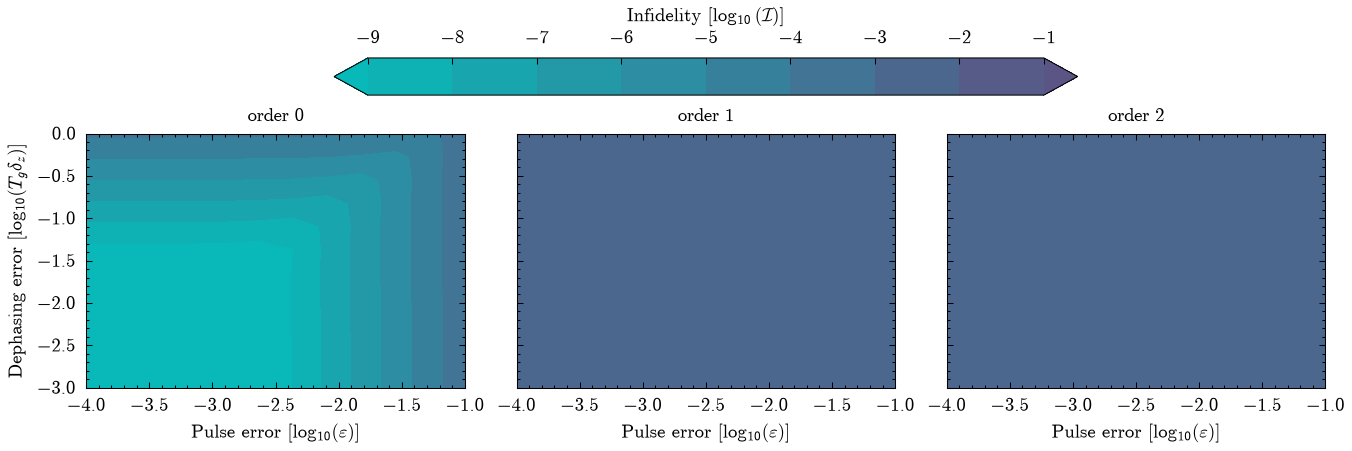

In [6]:
contours = {0: xs.load_result('contour_qubit_bare')}
for order in (1, 2):
    contours[order] = noise_experiments.simult_source_experiment(pulses[order], u_target)
    xs.save_result(f'contour_qubit_drag{order}', contours[order])

levels = np.arange(-9, 0)
fig, axs = plt.subplots(1, 3, figsize=(9, 3), layout='constrained', sharey=True)
for ax, order in zip(axs, orders):
    contour = plottools.plot_noise_contour(contours[order], levels=levels, ax=ax)
    ax.set_title(f'order {order}', fontsize=9)
for ax in axs[1:]:
    ax.set_ylabel('')
fig.colorbar(contour, ax=axs, location='top', shrink=0.6,
             label=r'Infidelity $[\log_{10}(\mathcal{I})]$')
plt.show()

The order-0 contour is low across most of the window. Orders 1 and 2 are
one color: the infidelity stays between about $2\times10^{-3}$ and
$4\times10^{-3}$ everywhere in this window, so the DRAG distortion of the
X gate is larger than the noise. The log-log sweeps above are where the
noise slope is visible.

## Three-level checks at 50 ns

Leakage and the coherent Stark error, simulated and calculated.

In [7]:
qutrit_rows = {}
qutrit_sims = {}
for order, pulse in pulses.items():
    simulated = simulator.simulate_qutrit(pulse, u_target, tg_alpha, lam=xs.LAM)
    calculated = drag.first_order_leakage(pulse, tg_alpha, lam=xs.LAM)
    budget = xs.error_budget(simulated['u_final'], u_target)
    qutrit_sims[order] = (simulated, calculated)
    qutrit_rows[f'order {order}'] = {
        'leakage, simulated': simulated['leakage'],
        'leakage, first order': calculated['leakage'],
        'peak, simulated': simulated['peak_leakage'],
        'peak, first order': calculated['leakage_trace'].max(),
        'Fourier proxy': drag.estimate_leakage(pulse, tg_alpha, lam=xs.LAM),
        'coherent infidelity': budget['coherent_infidelity'],
        'subspace infidelity': budget['subspace_infidelity'],
    }
pd.DataFrame(qutrit_rows)

,order 0,order 1,order 2
"leakage, simulated",0.020133,1.057020e-03,0.000951
"leakage, first order",0.015240,5.825987e-04,0.000543
"peak, simulated",0.051293,1.543495e-02,0.014812
"peak, first order",0.058181,1.673917e-02,0.016035
Fourier proxy,0.008414,1.506120e-13,0.000009
coherent infidelity,0.007047,1.760339e-05,0.000001
subspace infidelity,0.027106,1.074791e-03,0.000953


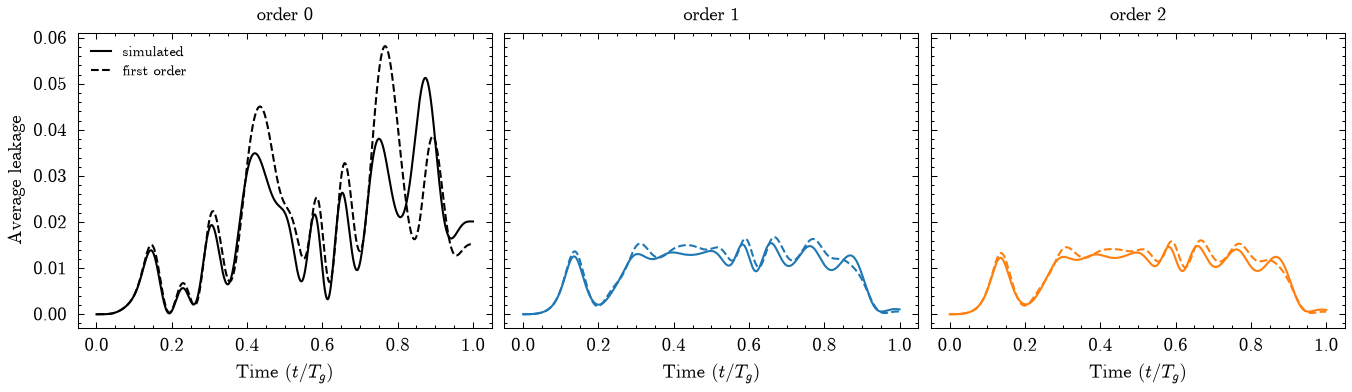

In [8]:
fig, axs = plt.subplots(1, 3, figsize=(9, 2.6), layout='constrained', sharey=True)
for ax, order in zip(axs, orders):
    simulated, calculated = qutrit_sims[order]
    ax.plot(simulated['times'], simulated['leakage_trace'], color=colors[order],
            label='simulated')
    ax.plot(calculated['times'], calculated['leakage_trace'], '--', color=colors[order],
            label='first order')
    ax.set_title(f'order {order}', fontsize=9)
    ax.set_xlabel(r'Time $(t/T_g)$')
axs[0].set_ylabel('Average leakage')
axs[0].legend(fontsize=7)
plt.show()

**Reading the table.**

- Order 1 cuts the final leakage from $2.0\times10^{-2}$ to
  $1.1\times10^{-3}$ and the coherent Stark error from $7.0\times10^{-3}$
  to $1.8\times10^{-5}$. The subspace infidelity falls from
  $2.7\times10^{-2}$ to $1.1\times10^{-3}$, and what remains is leakage.
- Order 2 improves the leakage only a little more, to $9.5\times10^{-4}$,
  because $|T_g\alpha|\approx 63$ is not a huge expansion parameter. It does
  remove the rest of the coherent error, down to $1.2\times10^{-6}$.
- The first-order calculation follows the transient and lands within a
  factor of about two of the simulated final leakage. The Fourier proxy
  drops by many orders and is not the leakage.

## Leakage against gate time

The same pulse at the gate times of notebook 02. Every DRAG term scales as
a power of $1/(T_g\alpha)$, so a longer gate is a smaller correction.

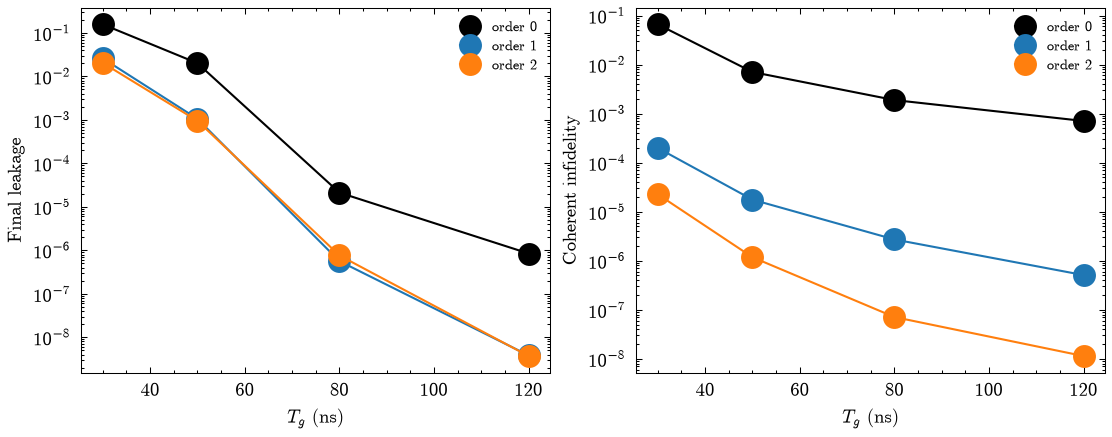

leakage  coherent infidelity  subspace infidelity  \
T_g (ns) order                                                           
30.0     0      1.573872e-01         6.600051e-02         2.173405e-01   
         1      2.598824e-02         1.992432e-04         2.629784e-02   
         2      2.043139e-02         2.265100e-05         2.052460e-02   
50.0     0      2.013271e-02         7.047211e-03         2.710559e-02   
         1      1.057020e-03         1.760339e-05         1.074791e-03   
         2      9.513004e-04         1.179090e-06         9.526294e-04   
80.0     0      2.122487e-05         1.888003e-03         1.909188e-03   
         1      5.631449e-07         2.713088e-06         3.276232e-06   
         2      7.614572e-07         7.106592e-08         8.325232e-07   
120.0    0      8.429963e-07         7.068573e-04         7.076997e-04   
         1      3.810986e-09         5.090052e-07         5.128162e-07   
         2      3.687538e-09         1.136866e-08         1.505620e-08   

                fidelity to X         |r_z|  
T_g (ns) order                               
30.0     0           1.000000  6.709620e-12  
         1           0.989772  1.796730e-01  
         2           0.987413  1.750698e-01  
50.0     0           1.000000  6.709620e-12  
         1           0.997551  1.053752e-01  
         2           0.997493  1.046864e-01  
80.0     0           1.000000  6.709620e-12  
         1           0.999100  6.556760e-02  
         2           0.999125  6.559133e-02  
120.0    0           1.000000  6.709620e-12  
         1           0.999585  4.373678e-02  
         2           0.999597  4.382654e-02

In [9]:
rows = []
for gate_time in xs.GATE_TIMES_NS:
    value = xs.tg_alpha(gate_time)
    for order in orders:
        pulse = drag.apply_drag(bare, value, order=order, beta=1.0, lam=xs.LAM)
        qutrit = simulator.simulate_qutrit(pulse, u_target, value, lam=xs.LAM)
        budget = xs.error_budget(qutrit['u_final'], u_target)
        vectors = simulator.first_order_error_vectors(pulse)
        qubit = simulator.simulate_control_dict(pulse, u_target)
        rows.append({
            'T_g (ns)': gate_time,
            'order': order,
            'leakage': qutrit['leakage'],
            'coherent infidelity': budget['coherent_infidelity'],
            'subspace infidelity': budget['subspace_infidelity'],
            'fidelity to X': qubit['avg_gate_fidelity'],
            '|r_z|': vectors['r_z_norm'],
        })
gate_scan = pd.DataFrame(rows)

fig, axs = plt.subplots(1, 2, figsize=(7.4, 2.9), layout='constrained')
for order in orders:
    part = gate_scan[gate_scan['order'] == order]
    axs[0].semilogy(part['T_g (ns)'], part['leakage'], 'o-', color=colors[order],
                    label=f'order {order}')
    axs[1].semilogy(part['T_g (ns)'], part['coherent infidelity'].clip(lower=1e-16),
                    'o-', color=colors[order], label=f'order {order}')
axs[0].set_ylabel('Final leakage')
axs[1].set_ylabel('Coherent infidelity')
for ax in axs:
    ax.set_xlabel(r'$T_g$ (ns)')
    ax.legend(fontsize=7)
plt.show()

gate_scan.set_index(['T_g (ns)', 'order'])

Longer gates need less help: the bare leakage is already $9\times10^{-7}$
at 120 ns. They also tolerate DRAG better. $|\vec r_z|$ and the missing
fidelity to X both shrink as $1/(T_g\alpha)$, because that is the size of
the correction. At 30 ns the correction is large enough that order 2, whose
terms carry higher powers of $1/(T_g\alpha)$, moves the qubit gate further
from X than order 1 does.

## Noise contours on the qutrit

Subspace infidelity at 50 ns. The order-0 map is the one from notebook 02.
Its floor is the bare leakage plus the Stark shift. Orders 1 and 2 lower
that floor to about $10^{-3}$.

Static additive dephasing and multiplicative driving field experiment



Multiplicative driving field error:	 0.00 %
	 \---- Static additive dephasing error:	16.67 %

	 \---- Static additive dephasing error:	41.67 %

	 \---- Static additive dephasing error:	66.67 %

	 \---- Static additive dephasing error:	83.33 %

...

Multiplicative driving field error:	91.67 %
	 \---- Static additive dephasing error:	 8.33 %

	 \---- Static additive dephasing error:	33.33 %

	 \---- Static additive dephasing error:	58.33 %

	 \---- Static additive dephasing error:	83.33 %

Multiplicative driving field error:	100.00%


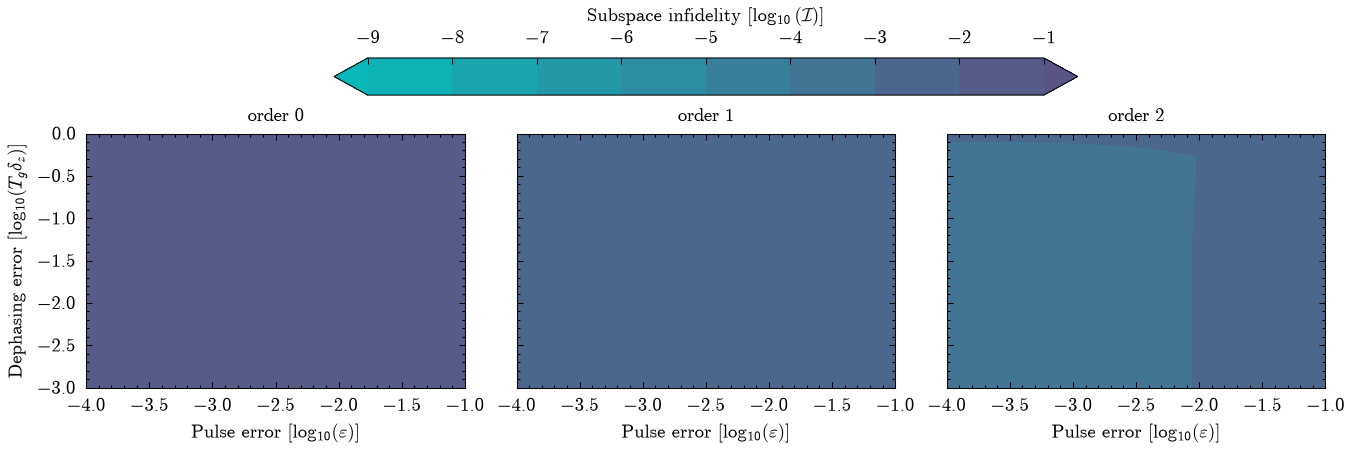

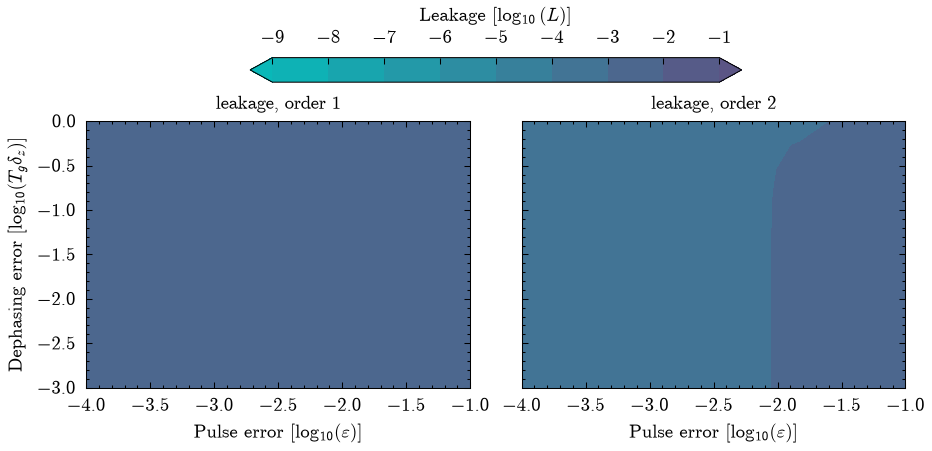

In [10]:
qutrit_contours = {0: xs.load_result('contour_qutrit_bare_50ns')}
for order in (1, 2):
    qutrit_contours[order] = noise_experiments.simult_source_experiment(
        pulses[order], u_target, tg_alpha=tg_alpha, lam=xs.LAM)
    xs.save_result(f'contour_qutrit_drag{order}_50ns', qutrit_contours[order])

fig, axs = plt.subplots(1, 3, figsize=(9, 3), layout='constrained', sharey=True)
for ax, order in zip(axs, orders):
    contour = plottools.plot_noise_contour(qutrit_contours[order], levels=levels, ax=ax)
    ax.set_title(f'order {order}', fontsize=9)
for ax in axs[1:]:
    ax.set_ylabel('')
fig.colorbar(contour, ax=axs, location='top', shrink=0.6,
             label=r'Subspace infidelity $[\log_{10}(\mathcal{I})]$')
plt.show()

fig, axs = plt.subplots(1, 2, figsize=(6.2, 3), layout='constrained', sharey=True)
for ax, order in zip(axs, (1, 2)):
    contour = plottools.plot_noise_contour(qutrit_contours[order], levels=levels, ax=ax,
                                           key='leakage_matrix')
    ax.set_title(f'leakage, order {order}', fontsize=9)
axs[1].set_ylabel('')
fig.colorbar(contour, ax=axs, location='top', shrink=0.6,
             label=r'Leakage $[\log_{10}(L)]$')
plt.show()

## Does DRAG give back the dephasing robustness?

On the qubit, no: the sweeps above show a restored slope of 2. On the
qutrit the bare pulse had already lost that cancellation, because the Stark
shift acts as an extra detuning. The DRAG detuning is built to cancel that
shift, so the qutrit comparison can go the other way.

`drag_dephasing_comparison` plots the subspace infidelity, floor included.
`sensitivity_sweep` removes the floor and shows the slope.

Static additive dephasing experiment



Static additive dephasing error:	37.50 %

Static additive dephasing error:	62.50 %

Static additive dephasing error:	100.00%

Static additive dephasing error:	 0.00 %

Static additive dephasing experiment


...

Static additive dephasing error:	100.00%

Static additive dephasing error:	25.00 %

Static additive dephasing experiment


Static additive dephasing error:	50.00 %

Static additive dephasing error:	87.50 %

Static additive dephasing error:	100.00%


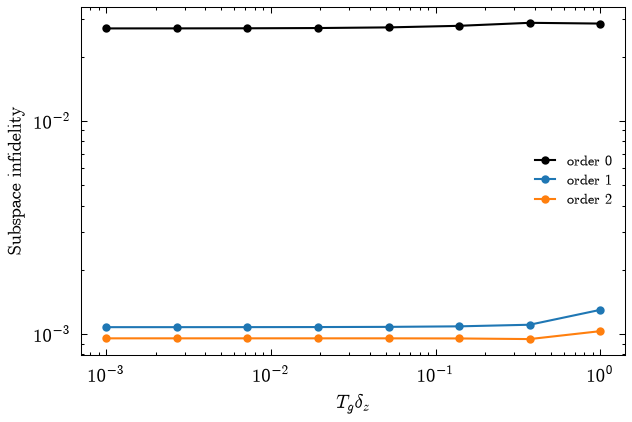

In [11]:
compared = {
    order: noise_experiments.drag_dephasing_comparison(
        bare, u_target, tg_alpha, order=order, beta=1.0, lam=xs.LAM, max_points=8)
    for order in (1, 2)
}

fig, ax = plt.subplots(figsize=(4.2, 2.8), layout='constrained')
reference = compared[1]
ax.loglog(reference['tg_delta_z'], reference['bare_infidelity'], 'k-o', ms=3, label='order 0')
for order, result in compared.items():
    ax.loglog(result['tg_delta_z'], result['drag_infidelity'], 'o-', ms=3,
              color=colors[order], label=f'order {order}')
ax.set_xlabel(r'$T_g\delta_z$')
ax.set_ylabel('Subspace infidelity')
ax.legend(fontsize=7)
plt.show()

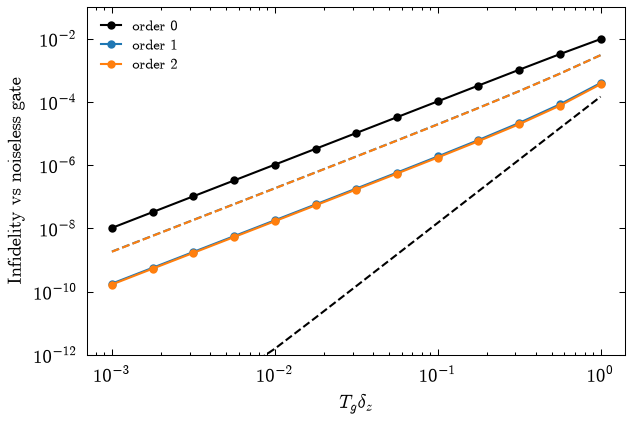

,order 0,order 1,order 2
qubit |r_z|,6.709620e-12,1.053752e-01,1.046864e-01
qubit slope,3.998504e+00,2.045773e+00,2.046579e+00
qutrit slope,1.995602e+00,2.073820e+00,2.069564e+00
qutrit S at 0.01,1.035150e-06,1.799970e-08,1.684328e-08


In [12]:
qutrit_sensitivity = {}
for order, pulse in pulses.items():
    qutrit_sensitivity[order] = xs.sensitivity_sweep(
        pulse, 'dephasing', tg_delta_z, u_target=u_target, tg_alpha_value=tg_alpha)

fig, ax = plt.subplots(figsize=(4.2, 2.8), layout='constrained')
for order in orders:
    ax.loglog(tg_delta_z, qubit_sweeps[order]['dephasing']['sensitivity'], '--',
              color=colors[order])
    ax.loglog(tg_delta_z, qutrit_sensitivity[order]['sensitivity'], 'o-', ms=3,
              color=colors[order], label=f'order {order}')
ax.set_xlabel(r'$T_g\delta_z$')
ax.set_ylabel('Infidelity vs noiseless gate')
ax.set_ylim(1e-12, 1e-1)
ax.legend(fontsize=7)
plt.show()

slope_window = (tg_delta_z >= 2e-2) & (tg_delta_z <= 0.3)
pd.DataFrame({
    f'order {order}': {
        'qubit |r_z|': qubit_sweeps[order]['vectors']['r_z_norm'],
        'qubit slope': xs.loglog_slope(
            tg_delta_z[slope_window],
            qubit_sweeps[order]['dephasing']['sensitivity'][slope_window]),
        'qutrit slope': xs.loglog_slope(tg_delta_z, qutrit_sensitivity[order]['sensitivity']),
        'qutrit S at 0.01': qutrit_sensitivity[order]['sensitivity'][
            int(np.argmin(np.abs(np.log10(tg_delta_z) + 2)))],
    }
    for order in orders
})

**Reading the robustness.**

- Dashed lines are the two-level result, solid lines the qutrit. Both have
  slope 2 once a first-order term is present.
- For the bare pulse the qutrit line lies far above the qubit line: the
  Stark shift is a dephasing error the curve was not designed to cancel.
- After DRAG the qutrit line lies *below* the qubit line. At
  $T_g\delta_z=0.01$ the sensitivity drops from $1.0\times10^{-6}$ (order 0)
  to $1.8\times10^{-8}$ (order 1). Cancelling the Stark shift removes more
  error than the DRAG correction itself adds, at this anharmonicity.
- Order 2 matches order 1 here. The two-level $|\vec r_z|$ still reports
  the opened curve, and that number remains the right estimate for a qubit
  that has no third level.

## Summary at 50 ns

| | order 0 | order 1 | order 2 |
| --- | --- | --- | --- |
| leakage | $2.0\times10^{-2}$ | $1.1\times10^{-3}$ | $9.5\times10^{-4}$ |
| coherent error | $7.0\times10^{-3}$ | $1.8\times10^{-5}$ | $1.2\times10^{-6}$ |
| fidelity to X | 1 | 0.9976 | 0.9975 |
| $\|\vec r_z\|$ | $\sim 0$ | 0.105 | 0.105 |
| qutrit dephasing sensitivity at $10^{-2}$ | $1.0\times10^{-6}$ | $1.8\times10^{-8}$ | $1.7\times10^{-8}$ |

DRAG does the job it is built for: it removes the leakage and the Stark
shift. It does not preserve the two-level dephasing cancellation, because
the correction is itself a detuning. On the qutrit, where that cancellation
was already lost, the net dephasing sensitivity improves. Notebook 04 asks
what happens when two of these pulses are played in a row.